In [1]:
# !pip install pandas numpy scikit-learn matplotlib wordcloud openpyxl

In [2]:
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from wordcloud import WordCloud

In [13]:
# PATH_DATA = r"C:\Users\lenovo\Downloads\praktikum_sentimen_listrik\Tweet_Data.csv"
PATH_DATA = None

ALIAS_KOLOM = {
    "created_at": ["created_at", "created at", "date", "tanggal", "waktu", "time", "timestamp", "datetime"],
    "username": ["username", "user_name", "user", "screen_name", "nama", "author", "name"],
    "full_text": ["full_text", "text", "tweet", "content", "isi", "komentar", "comment", "teks", "isi_tweet"],
}

def baca_file(path):
    if str(path).lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(path)
    for enc in ("utf-8-sig", "utf-8", "latin-1"):
        try:
            return pd.read_csv(path, sep=None, engine="python", encoding=enc)  # deteksi pemisah otomatis
        except UnicodeDecodeError:
            continue
    raise ValueError("File tidak dapat dibaca.")

if PATH_DATA:
    SUMBER = PATH_DATA
elif os.path.exists("tweet_data.csv"):
    SUMBER = "tweet_data.csv"
else:
    SUMBER = "tweet_data.xlsx"

df = baca_file(SUMBER)
df.columns = [str(c).strip() for c in df.columns]
peta = {}
for target, alias in ALIAS_KOLOM.items():
    for c in df.columns:
        if c.lower() in alias:
            peta[c] = target
            break
df = df.rename(columns=peta)
if "full_text" not in df.columns:
    raise ValueError(f"Kolom isi tweet tidak ditemukan. Kolom yang terbaca: {list(df.columns)}")
if "username" not in df.columns:
    df["username"] = "tidak_diketahui"
if "created_at" not in df.columns:
    df["created_at"] = pd.NaT
df = df[["created_at", "username", "full_text"]].dropna(subset=["full_text"]).copy()
df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")
print("Sumber data :", SUMBER)
print("Jumlah baris:", len(df))
df.head()

Sumber data : tweet_data.csv
Jumlah baris: 1200


,created_at,username,full_text
0,2026-10-20 15:22:00,user_1524,"Duh, aktivitas jadi lumpuh di Siantan, kesal s..."
1,2026-09-03 09:58:00,user_9295,"Duh, listrik padam lagi di Pontianak Barat, ke..."
2,2026-10-01 23:17:00,user_4652,"Alhamdulillah ya, jaringan sudah pulih di Tanj..."
3,2026-10-25 22:51:00,user_4433,Update: pasokan listrik normal dan stabil di P...
4,2026-10-27 07:10:00,user_6025,Terkini: rapat koordinasi pasokan listrik dige...


In [14]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)   # URL
    text = re.sub(r"@\w+", " ", text)                    # mention
    text = re.sub(r"#\w+", " ", text)                    # hashtag
    text = re.sub(r"\bRT\b", " ", text)                  # tanda retweet
    text = text.lower()                                  # case folding
    text = re.sub(r"[^a-z\s]", " ", text)                # simbol & angka
    text = re.sub(r"\s+", " ", text).strip()             # spasi berlebih
    return text

KAMUS_SLANG = {
    "gak": "tidak", "ga": "tidak", "nggak": "tidak", "ngga": "tidak", "enggak": "tidak",
    "engga": "tidak", "tdk": "tidak", "gk": "tidak", "tak": "tidak",
    "udah": "sudah", "udh": "sudah", "sdh": "sudah", "dah": "sudah",
    "yg": "yang", "dgn": "dengan", "dg": "dengan", "utk": "untuk", "untk": "untuk",
    "tp": "tapi", "krn": "karena", "karna": "karena", "krna": "karena",
    "bgt": "sekali", "banget": "sekali", "bngt": "sekali", "jg": "juga", "jga": "juga",
    "sy": "saya", "gue": "saya", "gw": "saya", "aku": "saya", "aja": "saja", "doang": "saja",
    "emg": "memang", "emang": "memang", "blm": "belum", "belom": "belum",
    "lg": "lagi", "lgi": "lagi", "skrg": "sekarang", "skrang": "sekarang",
    "bs": "bisa", "bsa": "bisa", "hrs": "harus", "org": "orang", "orng": "orang",
    "kmrn": "kemarin", "kalo": "kalau", "klo": "kalau", "kl": "kalau",
    "dr": "dari", "pd": "pada", "mlm": "malam", "pagi2": "pagi", "sm": "sama",
    "makasih": "terima kasih", "terimakasih": "terima kasih", "trims": "terima kasih",
    "thanks": "terima kasih", "thx": "terima kasih", "tq": "terima kasih",
    "padem": "padam", "mati2": "mati", "idup": "hidup", "nyala": "menyala",
    "byarpet": "byarpet", "bgmn": "bagaimana", "gmn": "bagaimana", "gimana": "bagaimana",
    "tlg": "tolong", "plis": "tolong", "pls": "tolong", "mohon2": "mohon",
    "pln": "pln", "pemadamannya": "pemadaman", "listriknya": "listrik",
}


def normalisasi_text(text: str) -> str:
    """Normalisasi: huruf berulang (paraaah -> parah) dan kata tidak baku/singkatan -> baku."""
    text = re.sub(r"(.)\1{2,}", r"\1", text)
    kata = [KAMUS_SLANG.get(k, k) for k in text.split()]
    return re.sub(r"\s+", " ", " ".join(kata)).strip()

df["clean_text"] = df["full_text"].apply(clean_text)          # cleansing
df["normal_text"] = df["clean_text"].apply(normalisasi_text)  # normalisasi
df = df[df["normal_text"].str.len() > 0].drop_duplicates(subset="normal_text").reset_index(drop=True)
print("Jumlah data setelah cleansing, normalisasi & hapus duplikat:", len(df))
df[["full_text", "clean_text", "normal_text"]].head()

Jumlah data setelah cleansing, normalisasi & hapus duplikat: 1167


,full_text,clean_text,normal_text
0,"Duh, aktivitas jadi lumpuh di Siantan, kesal s...",duh aktivitas jadi lumpuh di siantan kesal sekali,duh aktivitas jadi lumpuh di siantan kesal sekali
1,"Duh, listrik padam lagi di Pontianak Barat, ke...",duh listrik padam lagi di pontianak barat kesa...,duh listrik padam lagi di pontianak barat kesa...
2,"Alhamdulillah ya, jaringan sudah pulih di Tanj...",alhamdulillah ya jaringan sudah pulih di tanju...,alhamdulillah ya jaringan sudah pulih di tanju...
3,Update: pasokan listrik normal dan stabil di P...,update pasokan listrik normal dan stabil di po...,update pasokan listrik normal dan stabil di po...
4,Terkini: rapat koordinasi pasokan listrik dige...,terkini rapat koordinasi pasokan listrik digel...,terkini rapat koordinasi pasokan listrik digel...


In [15]:
berubah = df[df["clean_text"] != df["normal_text"]]
print(f"{len(berubah)} dari {len(df)} tweet berubah pada tahap normalisasi")
display(berubah[["clean_text", "normal_text"]].rename(
    columns={"clean_text": "sebelum normalisasi", "normal_text": "sesudah normalisasi"}).head(10))

# Contoh khusus kata gaul/tidak baku
contoh = ["Gak ada listrik udah lama bgt, paraaah!! @pln #matilampu https://t.co/x",
          "makasih yaa petugas, listrik udah nyala lg"]
display(pd.DataFrame({"sebelum": contoh,
                      "sesudah cleansing": [clean_text(t) for t in contoh],
                      "sesudah normalisasi": [normalisasi_text(clean_text(t)) for t in contoh]}))

58 dari 1167 tweet berubah pada tahap normalisasi


,sebelum normalisasi,sesudah normalisasi
12,yaelah keluhan warga tidak ditanggapi di sunga...,yaelah keluhan warga tidak ditanggapi di sunga...
51,capek deh byarpet terus tiap malam di pontiana...,capek deh byarpet terus tiap malam di pontiana...
86,yaelah mati lampu bergilir makin parah di jala...,yaelah mati lampu bergilir makin parah di jala...
111,lagi lagi mati lampu bergilir makin parah di p...,lagi lagi mati lampu bergilir makin parah di p...
158,parah keluhan warga tidak ditanggapi di sei ja...,parah keluhan warga tidak ditanggapi di sei ja...
168,lagi lagi gelap gulita seluruh kampung di tanj...,lagi lagi gelap gulita seluruh kampung di tanj...
171,lagi lagi aktivitas jadi lumpuh di kota baru k...,lagi lagi aktivitas jadi lumpuh di kota baru k...
177,capek deh aktivitas jadi lumpuh di sei jawi ke...,capek deh aktivitas jadi lumpuh di sei jawi ke...
195,parah mati listrik tanpa pemberitahuan di pont...,parah mati listrik tanpa pemberitahuan di pont...
202,yaelah aktivitas jadi lumpuh di jalan imam bon...,yaelah aktivitas jadi lumpuh di jalan imam bon...


,sebelum,sesudah cleansing,sesudah normalisasi
0,"Gak ada listrik udah lama bgt, paraaah!! @pln ...",gak ada listrik udah lama bgt paraaah,tidak ada listrik sudah lama sekali parah
1,"makasih yaa petugas, listrik udah nyala lg",makasih yaa petugas listrik udah nyala lg,terima kasih yaa petugas listrik sudah menyala...


In [16]:
KATA_POSITIF = {
    "menyala", "nyala", "pulih", "normal", "kembali", "lancar", "aman", "stabil",
    "terima kasih", "apresiasi", "sigap", "cepat", "tertangani", "teratasi",
    "berhasil", "membaik", "bantuan", "lega", "siaga", "kompensasi", "handal",
    "puas", "semangat", "dukungan", "bersyukur", "alhamdulillah",
}
KATA_NEGATIF = {
    "padam", "mati", "gelap", "gangguan", "mengganggu", "terganggu", "parah",
    "lama", "kecewa", "marah", "rugi", "kerugian", "rusak", "gagal", "buruk",
    "lumpuh", "keluhan", "sengsara", "menderita", "panas", "byarpet", "drop",
    "protes", "kesal", "capek", "tersiksa", "sering",
}
STOPWORD = {
    "yang", "di", "ke", "dan", "dari", "untuk", "dengan", "ini", "itu", "pada",
    "adalah", "atau", "juga", "karena", "akan", "ada", "tidak", "sudah", "saya",
    "kami", "kita", "mereka", "dalam", "oleh", "bisa", "udah", "nya", "aja",
    "yg", "dgn", "utk", "tp", "sih", "lah", "kok", "ya", "kan", "rt", "amp",
    "para", "sebagai", "lagi", "masih", "banget", "gak", "nggak", "ga",
}

def hitung_kata(clean, kamus):
    return sum(len(re.findall(rf"\b{re.escape(k)}\b", clean)) for k in kamus)

def label_sentimen(clean):
    pos, neg = hitung_kata(clean, KATA_POSITIF), hitung_kata(clean, KATA_NEGATIF)
    if pos > neg:
        return "positif"
    if neg > pos:
        return "negatif"
    return "netral"

df["sentimen"] = df["normal_text"].apply(label_sentimen)
df[["normal_text", "sentimen"]].head(10)

,normal_text,sentimen
0,duh aktivitas jadi lumpuh di siantan kesal sekali,negatif
1,duh listrik padam lagi di pontianak barat kesa...,negatif
2,alhamdulillah ya jaringan sudah pulih di tanju...,positif
3,update pasokan listrik normal dan stabil di po...,positif
4,terkini rapat koordinasi pasokan listrik digel...,netral
5,astaga listrik padam lagi di pontianak utara k...,negatif
6,ya ampun byarpet terus tiap malam di sei jawi ...,negatif
7,lagi lagi keluhan warga tidak ditanggapi di su...,negatif
8,update listrik sudah menyala kembali di sianta...,positif
9,catatan petugas melakukan inspeksi gardu di po...,netral


sentimen
positif    304
netral     339
negatif    524
Name: count, dtype: int64


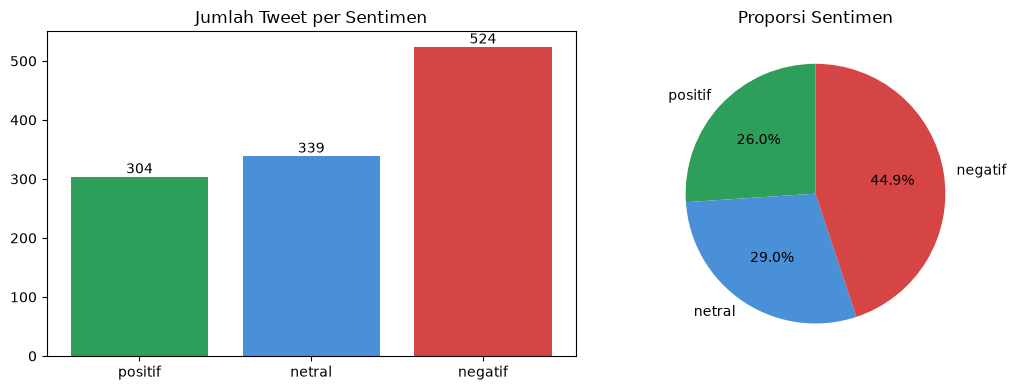

In [17]:
LABEL_ORDER = ["positif", "netral", "negatif"]
WARNA = {"positif": "#2e9e5b", "netral": "#4a90d9", "negatif": "#d64545"}

dist = df["sentimen"].value_counts().reindex(LABEL_ORDER).fillna(0).astype(int)
print(dist)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bars = axes[0].bar(dist.index, dist.values, color=[WARNA[l] for l in dist.index])
axes[0].bar_label(bars)
axes[0].set_title("Jumlah Tweet per Sentimen")
axes[1].pie(dist.values, labels=dist.index, colors=[WARNA[l] for l in dist.index],
            autopct="%1.1f%%", startangle=90)
axes[1].set_title("Proporsi Sentimen")
plt.tight_layout()
plt.show()

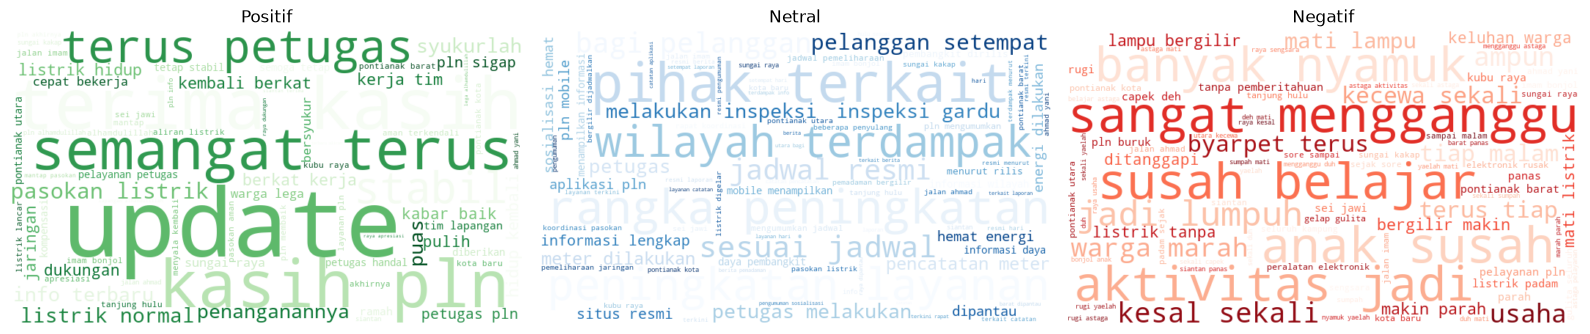

In [18]:
CMAP = {"positif": "Greens", "netral": "Blues", "negatif": "Reds"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, lab in zip(axes, LABEL_ORDER):
    teks = " ".join(df.loc[df["sentimen"] == lab, "normal_text"])
    ax.set_title(lab.capitalize())
    ax.axis("off")
    if teks.strip():
        wc = WordCloud(width=700, height=400, background_color="white", colormap=CMAP[lab],
                       stopwords=STOPWORD, max_words=100).generate(teks)
        ax.imshow(wc, interpolation="bilinear")
plt.tight_layout()
plt.show()

In [19]:
X, y = df["normal_text"], df["sentimen"]
strat = y if y.value_counts().min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=strat)

vec = TfidfVectorizer(ngram_range=(1, 2), stop_words=list(STOPWORD))
Xtr = vec.fit_transform(X_train)
Xte = vec.transform(X_test)

model = MLPClassifier(hidden_layer_sizes=(100,), activation="relu", solver="adam",
                      max_iter=300, random_state=42)
model.fit(Xtr, y_train)
y_pred = model.predict(Xte)
print(f"Data latih: {len(X_train)} | Data uji: {len(X_test)}")

Data latih: 933 | Data uji: 234


In [20]:
labels_ada = [l for l in LABEL_ORDER if l in set(y)]
p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)

ringkas = pd.DataFrame({
    "Metrik": ["Akurasi", "Presisi (weighted)", "Recall (weighted)", "F1-Score (weighted)"],
    "Nilai": [accuracy_score(y_test, y_pred), p, r, f]}).round(4)
display(ringkas)

print("Laporan per kelas:")
display(pd.DataFrame(classification_report(
    y_test, y_pred, labels=labels_ada, output_dict=True, zero_division=0)).T.round(3))

,Metrik,Nilai
0,Akurasi,1.0
1,Presisi (weighted),1.0
2,Recall (weighted),1.0
3,F1-Score (weighted),1.0


Laporan per kelas:


,precision,recall,f1-score,support
positif,1.0,1.0,1.0,61.0
netral,1.0,1.0,1.0,68.0
negatif,1.0,1.0,1.0,105.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,234.0
weighted avg,1.0,1.0,1.0,234.0


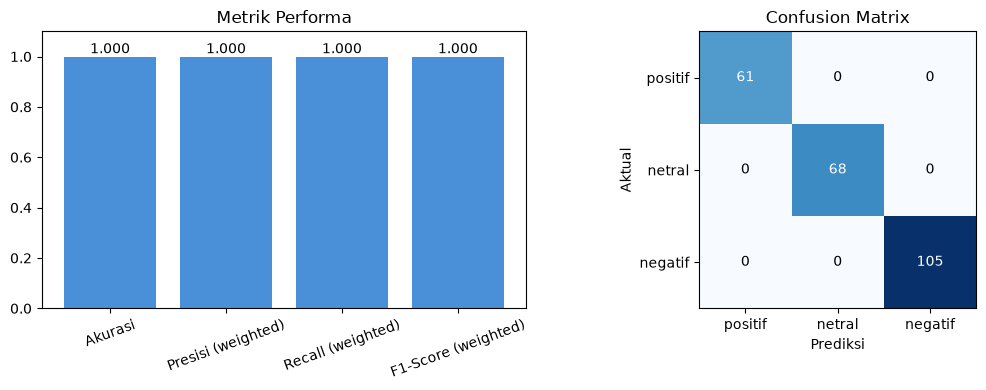

In [21]:
cm = confusion_matrix(y_test, y_pred, labels=labels_ada)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bars = axes[0].bar(ringkas["Metrik"], ringkas["Nilai"], color="#4a90d9")
axes[0].bar_label(bars, fmt="%.3f")
axes[0].set_ylim(0, 1.1)
axes[0].set_title("Metrik Performa")
axes[0].tick_params(axis="x", rotation=20)

im = axes[1].imshow(cm, cmap="Blues")
axes[1].set_xticks(range(len(labels_ada)), labels_ada)
axes[1].set_yticks(range(len(labels_ada)), labels_ada)
axes[1].set_xlabel("Prediksi")
axes[1].set_ylabel("Aktual")
axes[1].set_title("Confusion Matrix")
for i in range(len(labels_ada)):
    for j in range(len(labels_ada)):
        axes[1].text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()

In [22]:
EMOJI = {"positif": "😊", "netral": "😐", "negatif": "😠"}

def prediksi(teks):
    dibersihkan = clean_text(teks)
    bersih = normalisasi_text(dibersihkan)
    proba = model.predict_proba(vec.transform([bersih]))[0]
    hasil = model.classes_[int(np.argmax(proba))]
    print(f"Teks      : {teks}")
    print(f"Setelah cleansing  : {dibersihkan}")
    print(f"Setelah normalisasi: {bersih}")
    print(f"Prediksi  : {EMOJI[hasil]} {hasil.upper()}")
    for k, pr in zip(model.classes_, proba):
        print(f"  {EMOJI[k]} {k:8s}: {pr:.2%}")

prediksi("Listrik sudah menyala kembali, warga lega dan terima kasih kepada petugas PLN")

Teks      : Listrik sudah menyala kembali, warga lega dan terima kasih kepada petugas PLN
Setelah cleansing  : listrik sudah menyala kembali warga lega dan terima kasih kepada petugas pln
Setelah normalisasi: listrik sudah menyala kembali warga lega dan terima kasih kepada petugas pln
Prediksi  : 😊 POSITIF
  😠 negatif : 0.20%
  😐 netral  : 0.10%
  😊 positif : 99.70%


In [23]:
prediksi("Mati lampu terus tiap malam, kecewa banget dengan pelayanannya")

Teks      : Mati lampu terus tiap malam, kecewa banget dengan pelayanannya
Setelah cleansing  : mati lampu terus tiap malam kecewa banget dengan pelayanannya
Setelah normalisasi: mati lampu terus tiap malam kecewa sekali dengan pelayanannya
Prediksi  : 😠 NEGATIF
  😠 negatif : 99.60%
  😐 netral  : 0.17%
  😊 positif : 0.23%
